# Super user graphml

In [40]:
import pandas as pd
import networkx as nx
import statistics
import matplotlib.pyplot as plt
import random
import numpy as np

In [41]:
df = pd.read_csv("/content/sx-superuser.txt", sep=" ", names=["source", "target", "timestamp"])
df.head(20)

,source,target,timestamp
0,55,13,1247667441
1,8,13,1247667452
2,24,13,1247667461
3,27,13,1247667503
4,46,13,1247667554
5,48,13,1247667791
6,84,13,1247667902
7,8,63,1247668036
8,76,63,1247668038
9,137,63,1247668112


In [42]:
interacciones = df.groupby(["source", "target"]).size().reset_index(name="weight")
interacciones.head()

print("Interacciones originales:", len(df))
print("Aristas únicas:", len(interacciones))

Interacciones originales: 1443339
Aristas únicas: 924886


In [43]:
G = nx.from_pandas_edgelist(
    interacciones,
    source="source",
    target="target",
    edge_attr="weight",
    create_using=nx.DiGraph()
)

print("Vértices:", G.number_of_nodes())
print("Aristas:", G.number_of_edges())

Vértices: 194085
Aristas: 924886


In [44]:
nx.write_graphml(G, "superuser.graphml")

In [45]:
def degrees_list(G):
    return [d_v for (v, d_v) in G.degree()]

def AnalyzeGraph(G, verbose=True):
    print("Analyzing the graph.")
    print(f'There are {G.number_of_nodes()} nodes: {G.nodes() if verbose else "--"}')
    print(f'There are {G.number_of_edges()} edges: {G.edges() if verbose else "--"}')
    print(f'Average degree: {statistics.mean(degrees_list(G))}')
    print(f'Density: {nx.density(G)}')

# Tarefas

1. Calcular o número de vértices e de arestas, o grau médio dos vértices.
2. Calcular corretamente os coeficientes de clusterização global (ambos).
3. Calcular o coeficiente de clusterização de cada nó e plotar a sua distribuição.
4. Calcular a distância média entre os vértices.
5. Calcular o diâmetro do grafo.
6. Calcular a densidade.
7. Calcular e plotar a distribuição dos graus dos nós.
8. Calcular o número de componentes do grafo (no caso dos grafos não direcionados) e, se tiver mais de uma componente, plotar a distribuição dos tamanhos das componentes.
9. De forma complementar e opcional, fazer uma visualização do grafo (pode ser entregue em arquivo separado).

In [46]:
#1. Calcular o número de vértices e de arestas, o grau médio dos vértices.
AnalyzeGraph(G, verbose=False)

Analyzing the graph.
There are 194085 nodes: --
There are 924886 edges: --
Average degree: 9.530731380580674
Density: 2.4553109428342042e-05


In [47]:
#2. Calcular corretamente os coeficientes de clusterização global (ambos).
G2 = G.to_undirected()

grados = dict(G2.degree())
triangulos = nx.triangles(G2)

# 2.1. Clustering medio
clustering = {}
for nodo in G2.nodes():
    k = grados[nodo]
    if k < 2:
        clustering[nodo] = 0
    else:
        clustering[nodo] = (2 * triangulos[nodo]) / (k * (k - 1))

C_medio = sum(clustering.values()) / G2.number_of_nodes()
print("Clustering medio:", C_medio)

# 2.2. Transitividad
total_triangulos = sum(triangulos.values()) / 3
total_triplas = sum(k * (k - 1) / 2 for k in grados.values())

C_global = (3 * total_triangulos / total_triplas)
print("Transitividad:", C_global)

Clustering medio: 0.08194951933803815
Transitividad: 0.010550492441342619


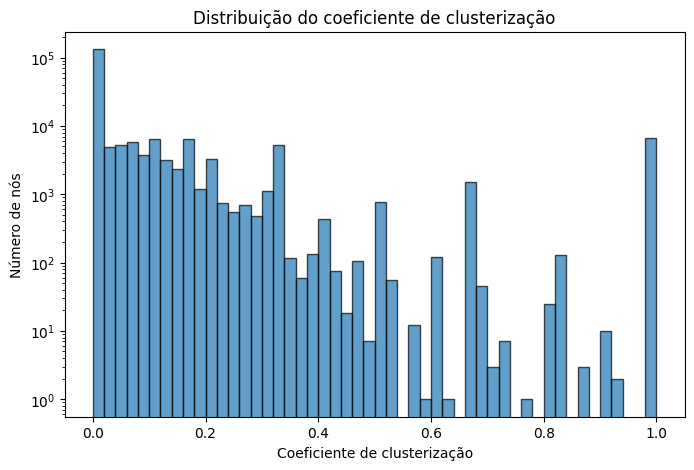

In [48]:
#3. Calcular o coeficiente de clusterização de cada nó e plotar a sua distribuição.
valores_clustering = list(clustering.values())
plt.figure(figsize=(8, 5))
plt.hist(
    valores_clustering,
    bins=50,
    edgecolor="black",
    alpha=0.7
)
plt.yscale("log")
plt.xlabel("Coeficiente de clusterização")
plt.ylabel("Número de nós")
plt.title("Distribuição do coeficiente de clusterização")

plt.show()

In [49]:
#4. Calcular a distância média entre os vértices.
print("Grafo conexo:", nx.is_connected(G2))

Grafo conexo: False


In [50]:
# Componente gigante
maior_componente = max(nx.connected_components(G2), key=len)
G_gigante = G2.subgraph(maior_componente)

print("Vértices de G2:", G2.number_of_nodes())
print("Vértices de la componente gigante:", G_gigante.number_of_nodes())

porcentaje = (
    G_gigante.number_of_nodes()
    / G2.number_of_nodes()
    * 100
)

print(f"Porcentaje de nodos: {porcentaje:.2f}%")

Vértices de G2: 194085
Vértices de la componente gigante: 189191
Porcentaje de nodos: 97.48%


In [51]:
# 4. Distância média entre os vértices
random.seed(42)

num_amostras = 100
nos_amostra = random.sample(list(G_gigante.nodes()), num_amostras)

distancias_medias = []

for i, nodo in enumerate(nos_amostra):
    distancias = nx.single_source_shortest_path_length(G_gigante, nodo)
    valores = [
        d for destino, d in distancias.items()
        if destino != nodo
    ]
    distancias_medias.append(sum(valores) / len(valores))
    if (i + 1) % 10 == 0:
        print(f"{i + 1}/{num_amostras} nós processados")
distancia_media = np.mean(distancias_medias)

print("Distância média aproximada:", distancia_media)

10/100 nós processados
20/100 nós processados
30/100 nós processados
40/100 nós processados
50/100 nós processados
60/100 nós processados
70/100 nós processados
80/100 nós processados
90/100 nós processados
100/100 nós processados

Distância média aproximada: 3.8170151170780695


In [52]:
#5. Calcular o diâmetro do grafo.

diametro = nx.approximation.diameter(G_gigante)
print("Diâmetro aproximado:", diametro)

Diâmetro aproximado: 12


In [53]:
# 6. Calcular a densidade

densidade = nx.density(G2)
print("Densidade:", densidade)

Densidade: 4.168325738932872e-05


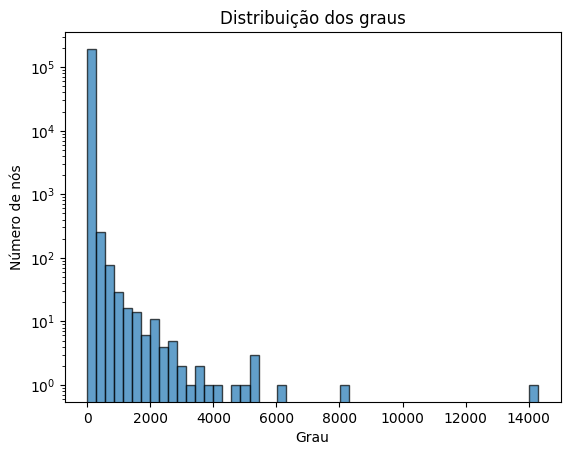

In [54]:
# 7. Calcular e plotar a distribuição dos graus dos nós

graus = [grau for nodo, grau in G2.degree()]

plt.hist(
    graus,
    bins=50,
    edgecolor="black",
    alpha=0.7
)
plt.xlabel("Grau")
plt.ylabel("Número de nós")
plt.title("Distribuição dos graus")
plt.yscale("log")

plt.show()

In [55]:
#8. Calcular o número de componentes do grafo (no caso dos grafos não direcionados) e, se tiver mais de uma componente,
# plotar a distribuição dos tamanhos das componentes.

componentes = list(nx.connected_components(G2))
num_componentes = len(componentes)
tamanhos = [len(componente) for componente in componentes]

print("Número de componentes:", num_componentes)
print("Tamanho da maior componente:", max(tamanhos))

Número de componentes: 3197
Tamanho da maior componente: 189191


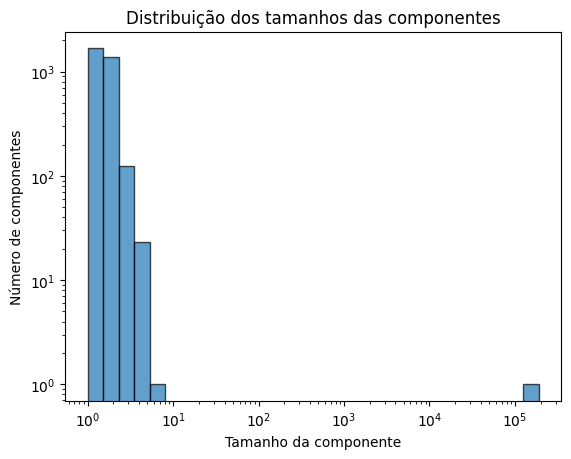

In [56]:
# 8. Distribuição dos tamanhos das componentes

import numpy as np

bins = np.logspace(
    np.log10(min(tamanhos)),
    np.log10(max(tamanhos)),
    30
)

plt.hist(
    tamanhos,
    bins=bins,
    edgecolor="black",
    alpha=0.7
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Tamanho da componente")
plt.ylabel("Número de componentes")
plt.title("Distribuição dos tamanhos das componentes")

plt.show()

Subgrafo
Nós: 128
Arestas: 4370


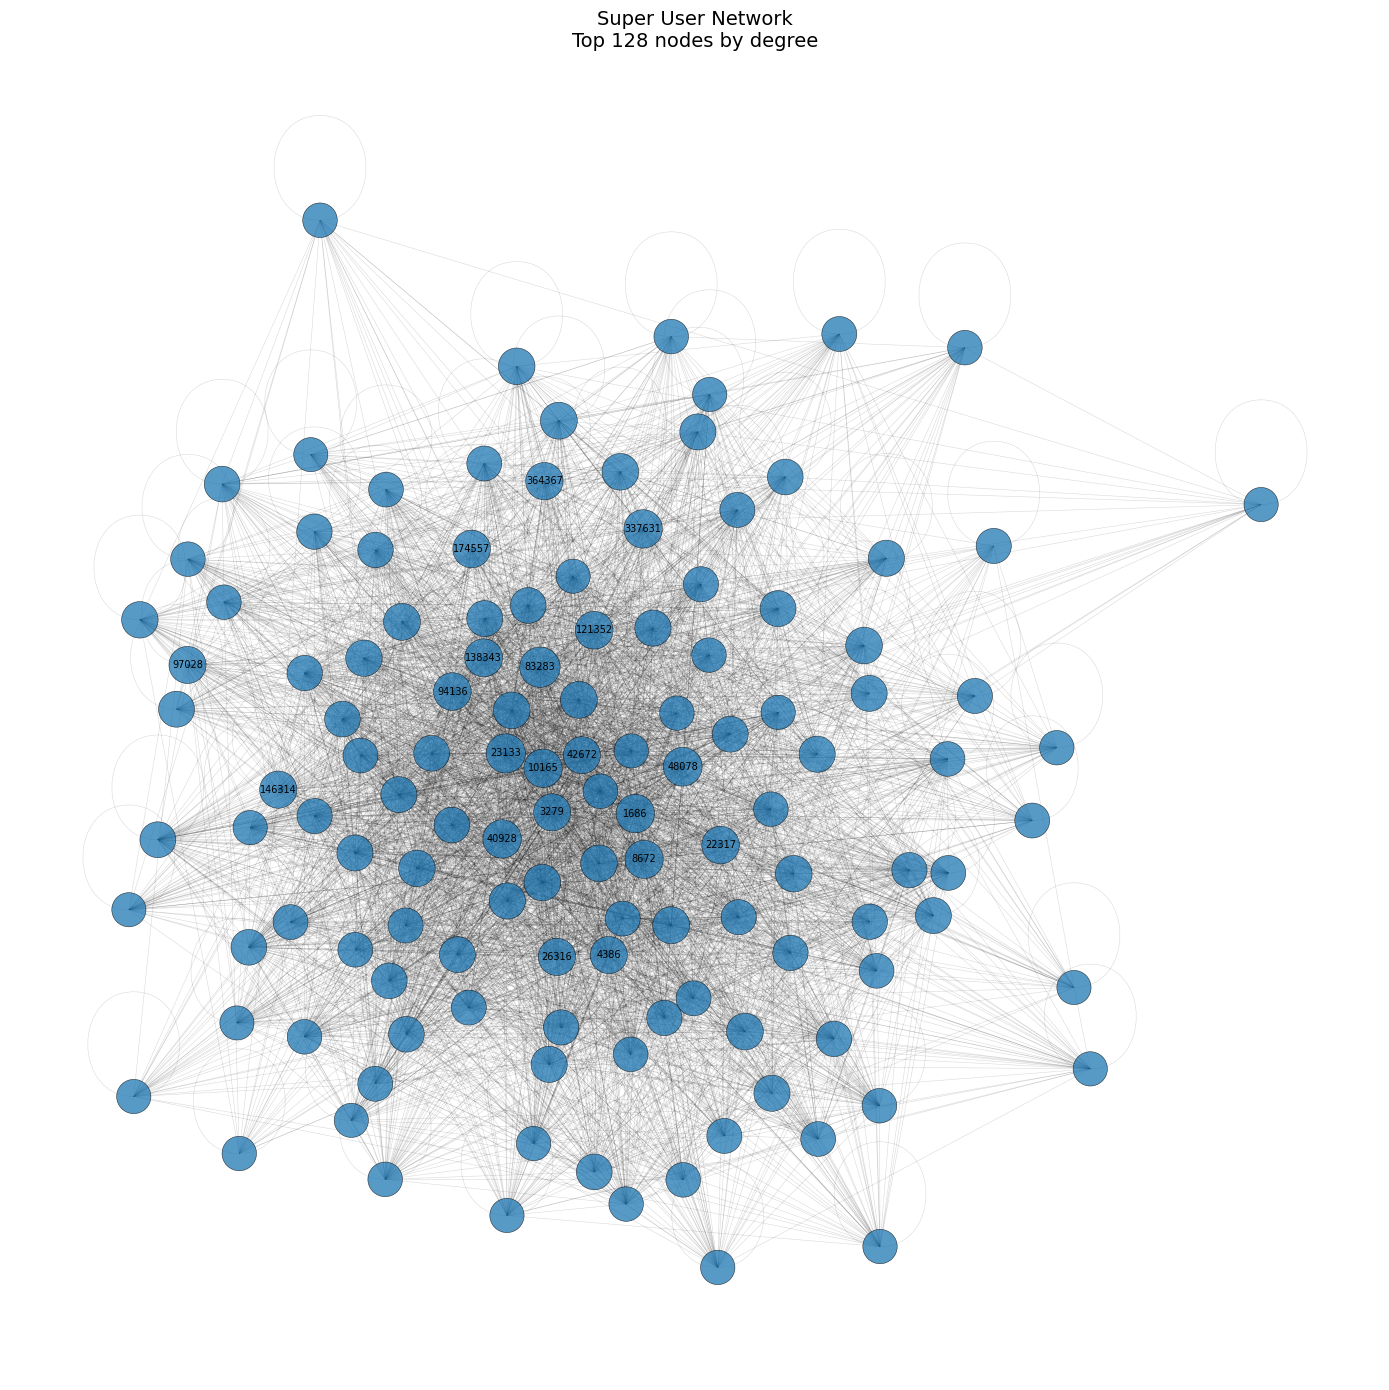

In [57]:
# 9. De forma complementar e opcional, fazer uma visualização
# do grafo.

N = 128

degree = dict(G2.degree())

# Selecionar os 128 nós com maior grau
top_nodes = sorted(
    degree,
    key=degree.get,
    reverse=True
)[:N]

# Criar subgrafo
H = G2.subgraph(top_nodes).copy()

print("Subgrafo")
print("Nós:", H.number_of_nodes())
print("Arestas:", H.number_of_edges())

# Tamanho dos nós de acordo com o grau
node_sizes = [
    80 + 80 * np.log1p(degree[node])
    for node in H.nodes()
]

# Posição dos nós
pos = nx.spring_layout(
    H,
    seed=42,
    k=2.5,
    iterations=100
)

plt.figure(figsize=(14, 14))

# Desenhar nós
nx.draw_networkx_nodes(
    H,
    pos,
    node_size=node_sizes,
    alpha=0.75,
    linewidths=0.4,
    edgecolors="black"
)

# Desenhar arestas
nx.draw_networkx_edges(
    H,
    pos,
    width=0.4,
    alpha=0.15
)

# Mostrar rótulos apenas dos 20 nós de maior grau
top20 = set(top_nodes[:20])

labels = {
    node: node
    for node in H.nodes()
    if node in top20
}

nx.draw_networkx_labels(
    H,
    pos,
    labels=labels,
    font_size=7
)

plt.title(
    "Super User Network\n"
    "Top 128 nodes by degree",
    fontsize=14
)

plt.axis("off")
plt.tight_layout()

# Para salvar:
# plt.savefig("superuser_top128.png", dpi=300, bbox_inches="tight")

plt.show()